In [1]:
import copy
from collections import Counter

import numpy as np

from qiskit import QuantumCircuit
from qiskit.circuit import Parameter
from qiskit_ibm_runtime import SamplerV2 as Sampler
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt
from numpy import random
from collections import namedtuple

import os
import pickle
from itertools import product
import networkx as nx
from scipy.optimize import minimize
from qiskit import transpile
from qiskit_ibm_runtime.fake_provider import FakeFez      # pick any fake device with enough qubits
from qiskit_aer import AerSimulator
from qiskit_aer.primitives import SamplerV2
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

In [2]:
results_path = "qaoa_noisy_results.pkl"

# Load earlier progress if the file exists
if os.path.exists(results_path):
    with open(results_path, "rb") as file:
        all_noisy_results = pickle.load(file)

results_path = "qaoa_results.pkl"

if os.path.exists(results_path):
    with open(results_path, "rb") as file:
        all_ideal_results = pickle.load(file)

In [3]:
# print(all_noisy_results)
all_graph_names = ["random_tr_g", "uniform_tr_g", "gauss_tr_g", "random_er_g", "uniform_er_g", "gauss_er_g", "random_fc_g", "uniform_fc_g", "gauss_fc_g", "random_ba_g", "uniform_ba_g", "gauss_ba_g"]

In [4]:
print(len(all_noisy_results))
print(len(all_noisy_results[0]))

360
16


In [5]:
def organize_results(all_results):
    organized = {}

    for record in all_results:
        graph = organized.setdefault(record["graph_index"], {"exact": {}, "layers": {}})

        graph["exact"] = {
            "all_bitstrings": record["all_bitstrings"],
            "all_costs": record["all_costs"],
            "cost_of": dict(zip(record["all_bitstrings"], record["all_costs"])),
            "exact_global_minimum": record["exact_global_minimum"],
            "exact_best_bitstring": record["exact_best_bitstring"],
        }

        circuit_stats = {
            key: value for key, value in record.items()
            if key.startswith(("logical_", "transpiled_"))
        }
        layer = graph["layers"].setdefault(record["num_layers"], {
            "parameter_names": record["parameter_names"],
            "circuit_stats": circuit_stats,
            "runs": {},
        })

        layer["runs"][record["init_name"]] = {
            "x0": record["x0"],
            "result": record["result"],
            "evaluations": record["evaluations"],
        }

    return organized

In [6]:
organized_ideal = organize_results(all_ideal_results)
organized_noisy = organize_results(all_noisy_results)

In [7]:
param_inits = 3

ideal_compiled_ARs = {}

for graph_index, graph_entry in organized_ideal.items():
    exact_min = graph_entry["exact"]["exact_global_minimum"]
    avg_AR_per_layer = []
    for num_layers, layer_entry in graph_entry["layers"].items():
        sum_AR = 0.0
        for init_name, run in layer_entry["runs"].items():
            sum_AR = run["result"].fun/exact_min
        averge_AR = sum_AR/param_inits
        avg_AR_per_layer.append(averge_AR)
    ideal_compiled_ARs[graph_index] = avg_AR_per_layer

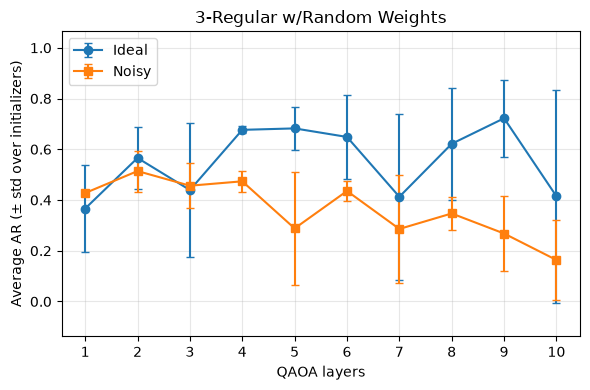

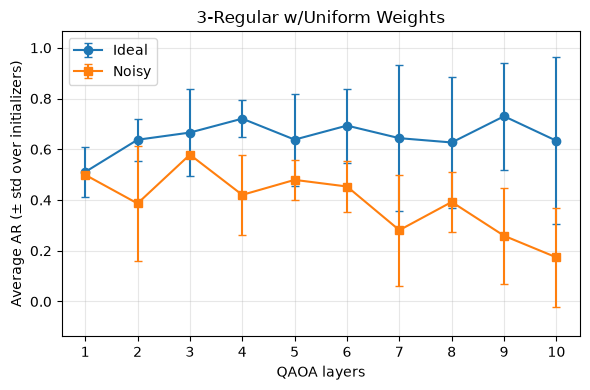

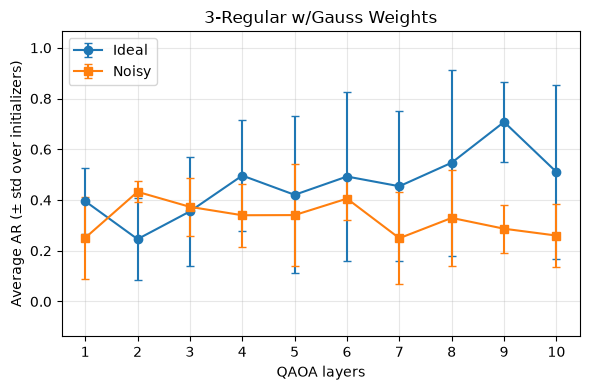

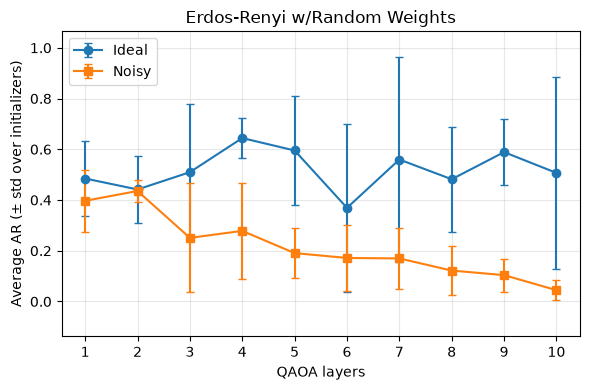

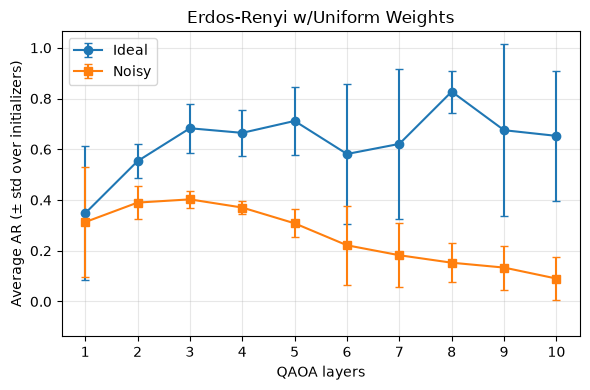

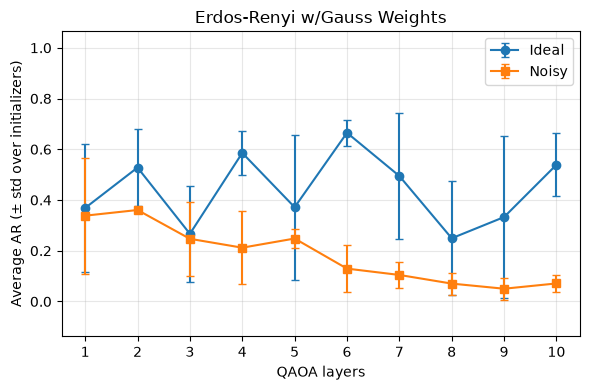

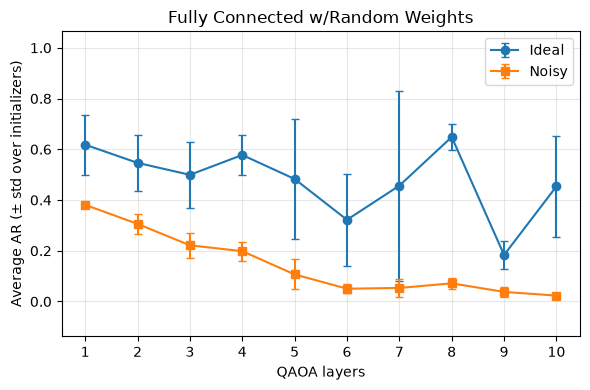

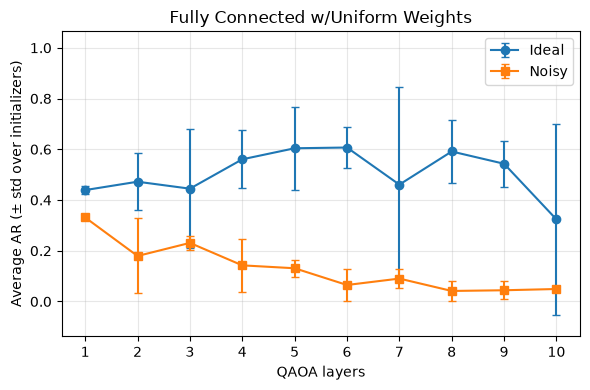

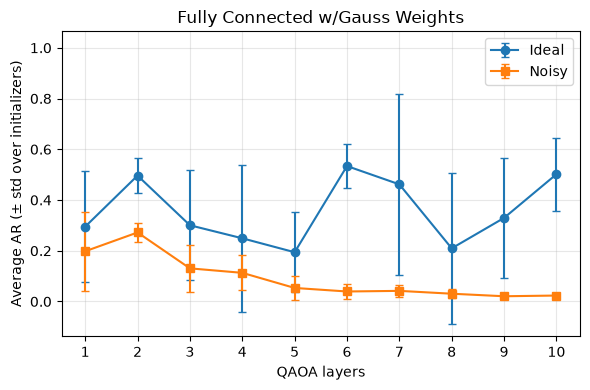

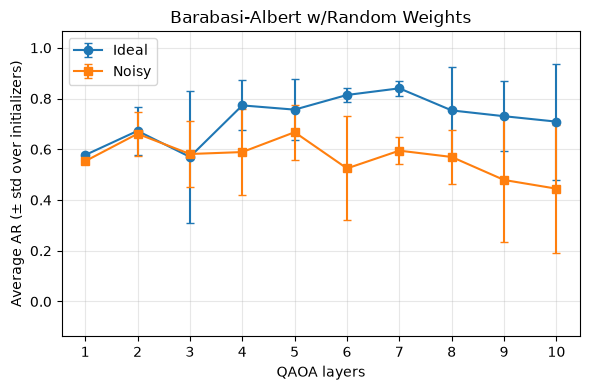

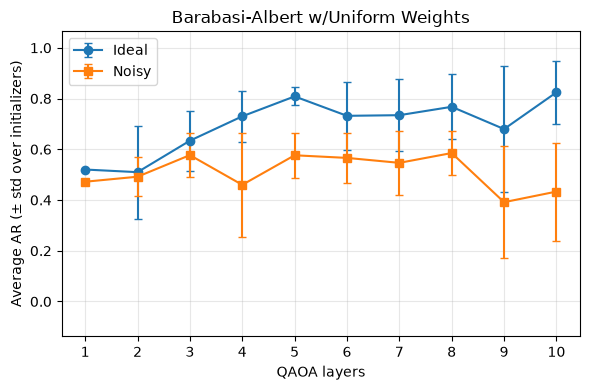

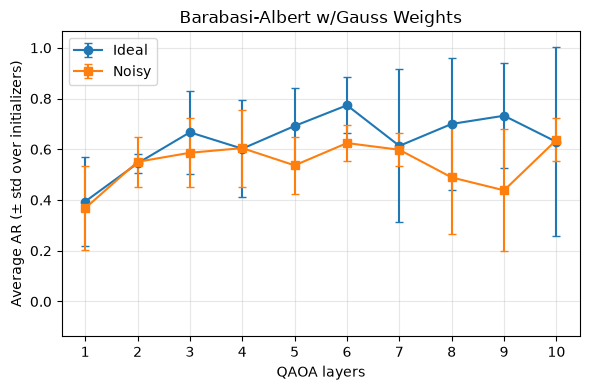

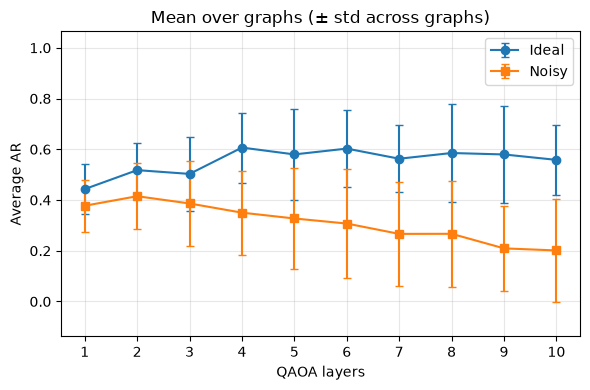

In [8]:
import os
import re
import numpy as np
import matplotlib.pyplot as plt


def compute_ar_statistics(organized):
    """Returns (means, stds): {graph_index: [value at layer 1, layer 2, ...]}.
    Mean and std are over the initializers' final AR at each layer count."""
    means, stds = {}, {}
    for graph_index, graph_entry in organized.items():
        exact_min = graph_entry["exact"]["exact_global_minimum"]
        means[graph_index], stds[graph_index] = [], []
        for num_layers, layer_entry in sorted(graph_entry["layers"].items()):
            ars = [run["result"].fun / exact_min for run in layer_entry["runs"].values()]
            means[graph_index].append(np.mean(ars))
            stds[graph_index].append(np.std(ars, ddof=1) if len(ars) > 1 else 0.0)
    return means, stds


ideal_means, ideal_stds = compute_ar_statistics(organized_ideal)
noisy_means, noisy_stds = compute_ar_statistics(organized_noisy)

graph_names = ["3-Regular w/Random Weights", "3-Regular w/Uniform Weights", "3-Regular w/Gauss Weights",
               "Erdos-Renyi w/Random Weights", "Erdos-Renyi w/Uniform Weights", "Erdos-Renyi w/Gauss Weights",
               "Fully Connected w/Random Weights", "Fully Connected w/Uniform Weights", "Fully Connected w/Gauss Weights",
               "Barabasi-Albert w/Random Weights", "Barabasi-Albert w/Uniform Weights", "Barabasi-Albert w/Gauss Weights"]   # ... one per graph
first_graph_index = 0

output_directory = "ar_plots"
os.makedirs(output_directory, exist_ok=True)


def graph_title(graph_index):
    position = graph_index - first_graph_index
    return graph_names[position] if 0 <= position < len(graph_names) else f"Graph {graph_index}"


def safe_filename(text):
    return re.sub(r"[^A-Za-z0-9_-]+", "_", text).strip("_")


graph_indices = sorted(ideal_means.keys() & noisy_means.keys())

lows = [m - s for g in graph_indices for m, s in zip(ideal_means[g] + noisy_means[g], ideal_stds[g] + noisy_stds[g])]
highs = [m + s for g in graph_indices for m, s in zip(ideal_means[g] + noisy_means[g], ideal_stds[g] + noisy_stds[g])]
y_limits = (min(lows) - 0.05, max(highs) + 0.05)

# ---- One image per graph, with std bars ----
for graph_index in graph_indices:
    title = graph_title(graph_index)
    fig, ax = plt.subplots(figsize=(6, 4))
    for label, means, stds, marker in [("Ideal", ideal_means, ideal_stds, "o"),
                                       ("Noisy", noisy_means, noisy_stds, "s")]:
        layers = np.arange(1, len(means[graph_index]) + 1)
        ax.errorbar(layers, means[graph_index], yerr=stds[graph_index],
                    marker=marker, capsize=3, label=label)
    ax.set_title(title)
    ax.set_xlabel("QAOA layers")
    ax.set_ylabel("Average AR (± std over initializers)")
    ax.set_xticks([1,2,3,4,5,6,7,8,9,10])
    ax.set_ylim(y_limits)
    ax.grid(alpha=0.3)
    ax.legend()
    fig.tight_layout()
    fig.savefig(f"{output_directory}/{graph_index:02d}_{safe_filename(title)}.png", dpi=200)
    plt.show()
    plt.close(fig)

# ---- Mean over graphs, with std across graphs ----
fig, ax = plt.subplots(figsize=(6, 4))
for label, means, marker in [("Ideal", ideal_means, "o"), ("Noisy", noisy_means, "s")]:
    values = np.array([means[g] for g in graph_indices])      # shape (graphs, layers)
    layers = np.arange(1, values.shape[1] + 1)
    ax.errorbar(layers, values.mean(axis=0), yerr=values.std(axis=0, ddof=1),
                marker=marker, capsize=3, label=label)
ax.set_title("Mean over graphs (± std across graphs)")
ax.set_xlabel("QAOA layers")
ax.set_ylabel("Average AR")
ax.set_xticks(layers)
ax.set_ylim(y_limits)
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(f"{output_directory}/mean_over_graphs.png", dpi=200)
plt.show()
plt.close(fig)

In [9]:
noisy_circuit_stats = {}

for graph_index, graph_entry in organized_noisy.items():
    per_layer = []
    for num_layers, layer_entry in graph_entry["layers"].items():
        gate_count = layer_entry["circuit_stats"]["transpiled_two_qubit_gates"]
        depth = layer_entry["circuit_stats"]["transpiled_depth"]
        per_layer.append([gate_count, depth])
    noisy_circuit_stats[graph_index] = per_layer

In [10]:
print(noisy_circuit_stats)

{0: [[57, 108], [129, 246], [216, 350], [297, 474], [369, 615], [480, 725], [576, 856], [636, 1248], [717, 1224], [837, 1213]], 1: [[57, 117], [138, 222], [213, 421], [300, 549], [372, 573], [474, 681], [540, 980], [570, 964], [720, 1405], [807, 1285]], 2: [[57, 98], [132, 218], [222, 376], [309, 477], [384, 639], [465, 779], [564, 889], [606, 978], [708, 1297], [795, 1433]], 3: [[122, 261], [283, 556], [432, 865], [551, 1133], [712, 1408], [846, 1734], [1070, 1902], [1216, 2424], [1305, 2609], [1586, 2991]], 4: [[119, 261], [259, 559], [420, 785], [563, 1130], [748, 1430], [894, 1744], [1046, 1958], [1240, 2393], [1395, 2564], [1562, 2973]], 5: [[107, 231], [244, 553], [423, 794], [611, 1238], [754, 1413], [885, 1769], [1085, 1954], [1201, 2403], [1341, 2716], [1502, 3021]], 6: [[204, 424], [438, 749], [663, 1120], [867, 1579], [1113, 1811], [1341, 2278], [1506, 2834], [1785, 2986], [1950, 3275], [2238, 3870]], 7: [[207, 409], [429, 745], [660, 1078], [888, 1465], [1113, 1975], [1338,

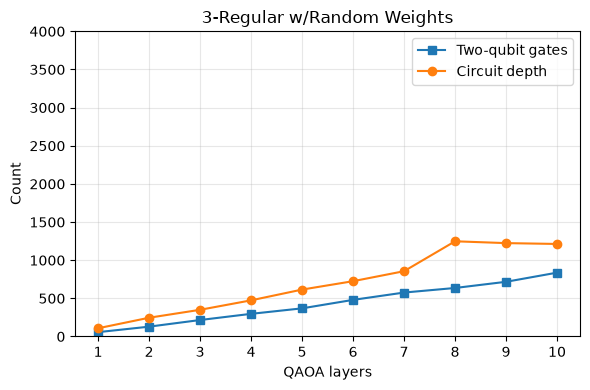

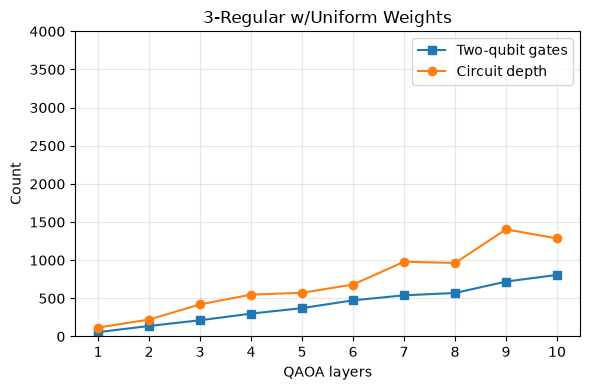

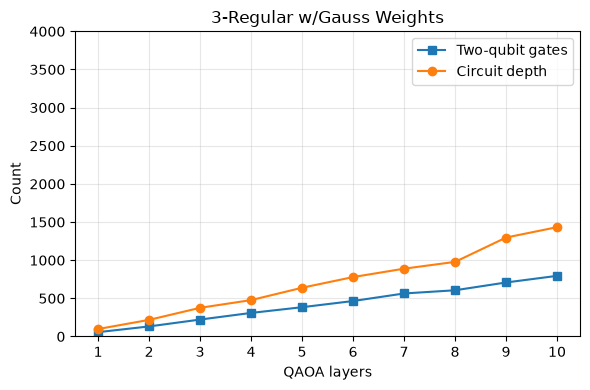

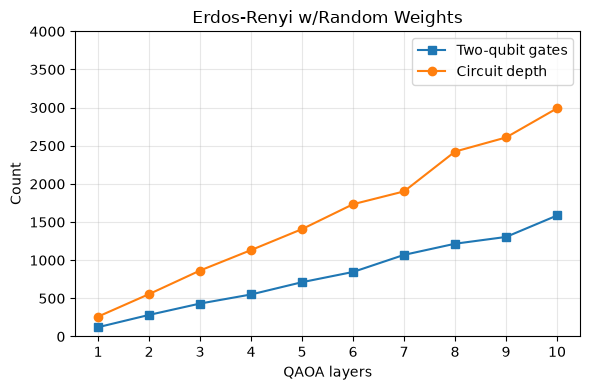

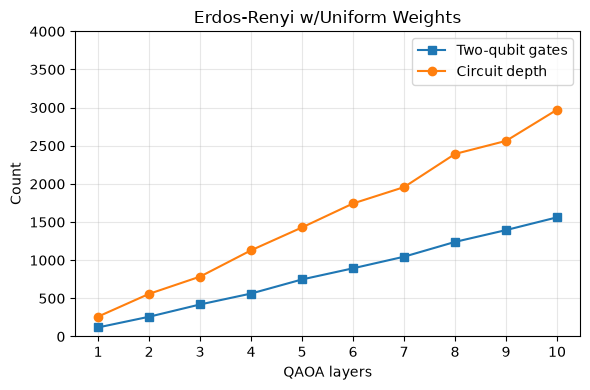

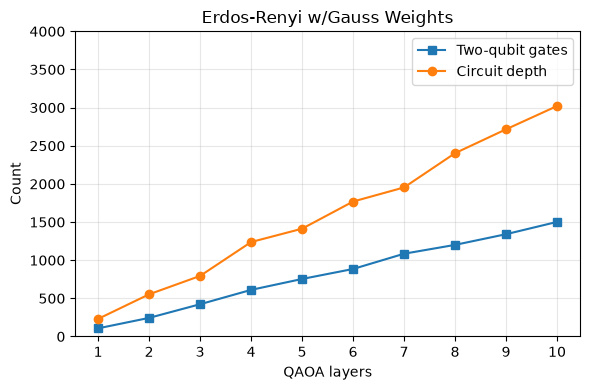

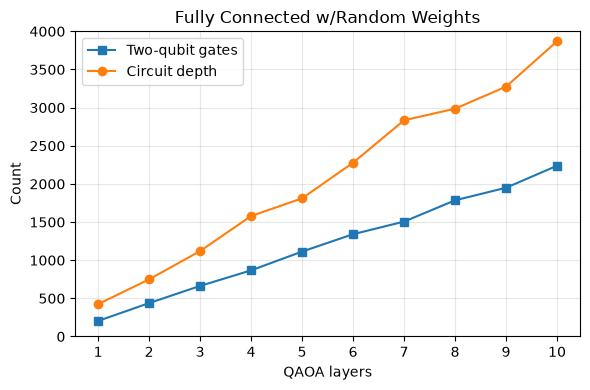

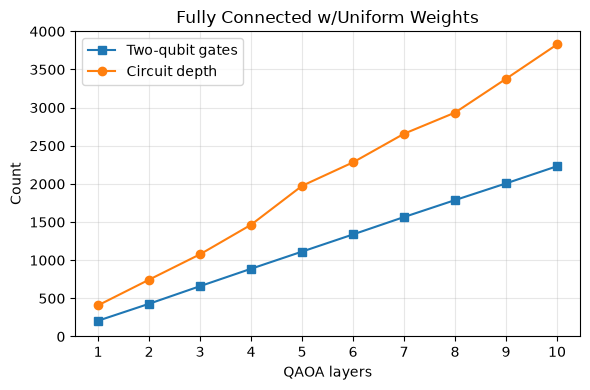

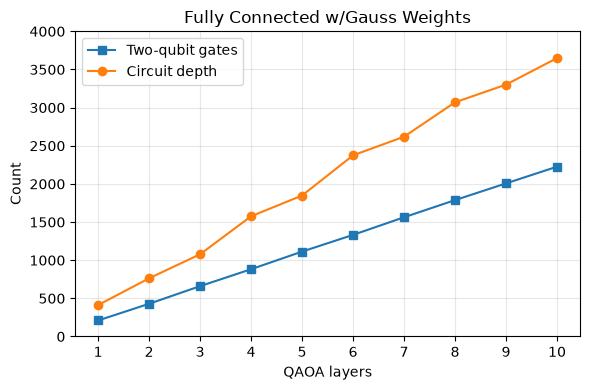

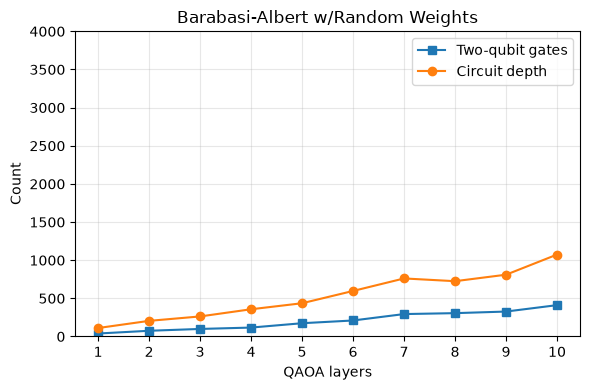

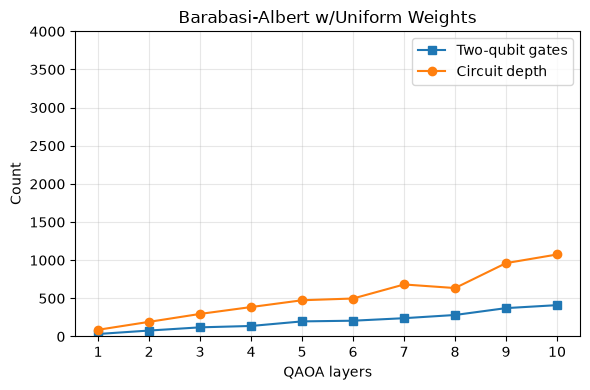

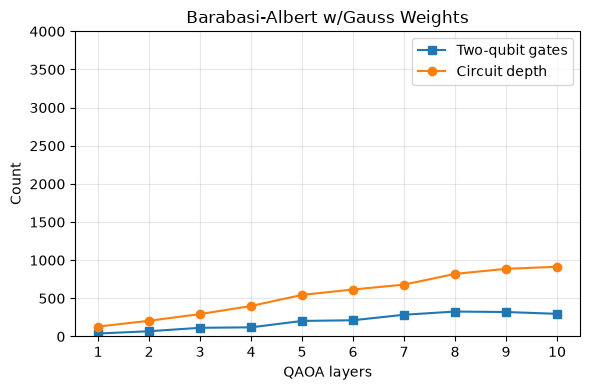

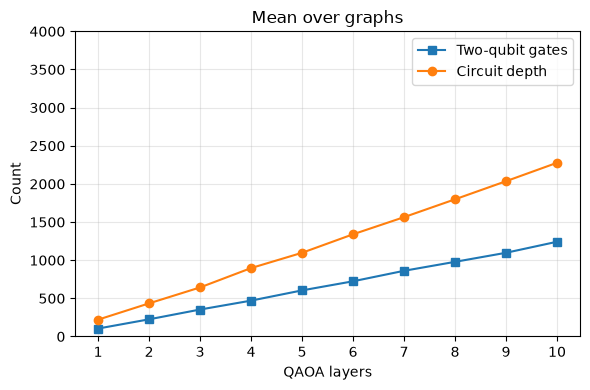

In [12]:
output_directory = "gate_plots"
os.makedirs(output_directory, exist_ok=True)


def plot_gate_stats(pairs, title, filename):
    pairs = np.array(pairs)                      # shape (layers, 2)
    layers = np.arange(1, len(pairs) + 1)

    fig, ax = plt.subplots(figsize=(6, 4))
    ax.plot(layers, pairs[:, 0], marker="s", label="Two-qubit gates")
    ax.plot(layers, pairs[:, 1], marker="o", label="Circuit depth")
    ax.set_title(title)
    ax.set_xlabel("QAOA layers")
    ax.set_ylabel("Count")
    ax.set_ylim(0, 4000)
    ax.set_xticks(layers)
    ax.grid(alpha=0.3)
    ax.legend()
    fig.tight_layout()
    fig.savefig(f"{output_directory}/{filename}.png", dpi=200)
    plt.show()
    plt.close(fig)


# One image per graph
for graph_index, pairs in noisy_circuit_stats.items():
    plot_gate_stats(pairs, graph_names[graph_index], f"graph_{graph_index}")

# One image for the mean over graphs
mean_pairs = np.mean([noisy_circuit_stats[g] for g in noisy_circuit_stats], axis=0)
plot_gate_stats(mean_pairs, "Mean over graphs", "mean_over_graphs")